# Warehouse Traffic Hotspots — Many Maps, Many Scenarios

**Question:** Where do warehouse robots crowd together, and does congestion-aware routing help? And does the answer hold across **different warehouse layouts** and **different robot start/goal lists**?

**Everyday analogy:** On Google Maps, if everyone takes the fastest road, that road jams. If Maps sends some people on a slightly longer road, traffic spreads out and nobody loses much time. We test exactly this idea, on four warehouse maps and several random scenario files each.

**Data:** every `warehouse-*.map` in `mapf-map/` (4 layouts) and up to `SCENS_PER_MAP` random scenario files per map from `scen-random/`. Each scenario file has 1000 start/goal pairs (one pair = one robot); we sample `NUM_ROBOTS` of them.

| Step | What we do | What we get |
|---|---|---|
| 1 | Load every warehouse map and build one graph per layout | A graph per map |
| 2 | Route robots on every map/scenario pair, with and without congestion awareness | Comparison table + charts |
| 3 | Zoom into one map: heatmaps, hotspots, alpha sweep | Pictures and a hotspot ranking |
| 4 | Block the busiest cell on that map | How much longer trips get |
| 5 | Write the findings | Summary sentences |

With the default settings this routes 4 maps x 5 scenarios x 200 robots twice — about a minute.

## Setup

In [18]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# ---------- Settings (change these) ----------
MAP_DIR  = Path("mapf-map")
SCEN_DIR = Path("scen-random")

SCENS_PER_MAP = 5    # scenario files per map (None = all 25, slower)
NUM_ROBOTS    = 200  # robots sampled from each scenario file
ALPHA         = 0.1  # how strongly robots avoid busy aisles (0 = ignore traffic)
SEED          = 42   # fixes the random robot sample and its order

FREE_CELLS = ".GS"   # map characters a robot can walk on ('@' = shelf/wall)
plt.rcParams["figure.dpi"] = 110

## Step 1: Find the data and build one graph per map

- A `.map` file is a grid of characters: `.` = free floor, `@` = shelf or wall.
- A `.scen` file has one line per robot: where it starts and where it wants to go.
- We find all `warehouse-*.map` files, then look for their `...-random-N.scen` files.
- **The graph is built once per map** and reused for every scenario file of that map.

A cell is written as **(x, y)**: x = column, y = row. Every free cell becomes a node, and two neighbouring free cells are joined by an edge.

In [19]:
def load_map(path):
    """Read a .map file and return the grid as a list of text rows (row 0 = top)."""
    lines = Path(path).read_text().splitlines()
    lines = [line.strip() for line in lines]

    first_grid_line = lines.index("map") + 1
    grid_lines = lines[first_grid_line:]

    return [row for row in grid_lines if row]


def load_robots(path):
    """Read a .scen file and return one (start, goal) pair per robot."""
    lines = Path(path).read_text().splitlines()
    robot_lines = lines[1:]          # line 0 is the header "version 1"

    robots = []
    for line in robot_lines:
        if not line.strip():
            continue
        columns = line.split()
        coordinates = columns[4:8]
        start_x, start_y, goal_x, goal_y = [int(value) for value in coordinates]
        robots.append(((start_x, start_y), (goal_x, goal_y)))

    return robots

In [20]:
def build_graph(map_rows):
    """One node per free cell, one edge per up/down/left/right move."""
    height = len(map_rows)
    width = len(map_rows[0])

    G = nx.grid_2d_graph(width, height)

    # Remove the cells a robot cannot stand on ('@' = shelf/wall).
    for y in range(height):
        for x in range(width):
            if map_rows[y][x] not in FREE_CELLS:
                G.remove_node((x, y))

    return G


warehouse_maps = sorted(MAP_DIR.glob("warehouse*.map"))

map_rows_by_name = {}
graphs = {}

for map_file in warehouse_maps:
    rows = load_map(map_file)
    map_rows_by_name[map_file.name] = rows
    graphs[map_file.name] = build_graph(rows)

print("Built graphs for", len(warehouse_maps), "warehouse maps")

Built graphs for 4 warehouse maps


In [21]:
def scen_number(path):
    """Turn "...-random-12.scen" into 12, so files sort 1, 2, ..., 10 (not 1, 10, 2)."""
    return int(path.stem.rsplit("-", 1)[1])


datasets = []
for map_file in warehouse_maps:
    scen_files = sorted(SCEN_DIR.glob(f"{map_file.stem}-random-*.scen"), key=scen_number)
    if SCENS_PER_MAP is not None:
        scen_files = scen_files[:SCENS_PER_MAP]
    for scen_file in scen_files:
        datasets.append((map_file, scen_file))

map_table = []
for map_file in warehouse_maps:
    rows = map_rows_by_name[map_file.name]
    G = graphs[map_file.name]
    map_table.append({
        "map": map_file.stem.replace("warehouse-", ""),
        "size": f"{len(rows[0])} x {len(rows)}",
        "free cells": G.number_of_nodes(),
        "possible moves": G.number_of_edges(),
        "regions": nx.number_connected_components(G),
    })

print(f"{len(warehouse_maps)} maps, {len(datasets)} map/scenario pairs")
pd.DataFrame(map_table)

4 maps, 20 map/scenario pairs


,map,size,free cells,possible moves,regions
0,10-20-10-2-1,161 x 63,5699,8778,1
1,10-20-10-2-2,170 x 84,9776,16902,1
2,20-40-10-2-1,321 x 123,22599,35158,1
3,20-40-10-2-2,340 x 164,38756,67412,1


## Step 2: Route robots on every map and scenario

For each map/scenario pair:

1. take the start/goal pairs from the scenario file,
2. keep the usable ones (start and goal are free cells and differ),
3. sample `NUM_ROBOTS` of them with a fixed seed,
4. route them twice — once with plain shortest paths, once with congestion-aware costs.

The congestion-aware cost of a segment is **1 + ALPHA x (robots already using it)**, so busy aisles look longer and later robots avoid them. We then compare the **busiest segment** and the **10 busiest segments** before and after.

In [22]:
def edge_name(a, b):
    """A name for the segment between two neighbouring cells, the same in both directions."""
    return tuple(sorted([a, b]))


def route_robots(graph, robots, alpha=0):
    """Send every robot from start to goal, one robot after another.

    alpha = 0  -> every robot takes its shortest path and ignores traffic.
    alpha > 0  -> a segment costs 1 + alpha * (robots already using it).

    Returns:
        paths    -> one route per robot (None if no route exists)
        edge_use -> how many robots use each segment
    """
    edge_use = {}               # segment name -> number of robots using it
    paths = []                  # one entry per robot, in the same order

    def segment_cost(a, b, edge_data):
        # NetworkX calls this for every segment. edge_data is not needed here.
        robots_on_segment = edge_use.get(edge_name(a, b), 0)
        return 1 + alpha * robots_on_segment

    for start, goal in robots:
        weight = segment_cost if alpha > 0 else None

        try:
            path = nx.shortest_path(graph, start, goal, weight=weight)
        except nx.NetworkXNoPath:
            paths.append(None)          # no route: keep the list aligned with robots
            continue

        paths.append(path)

        # Add one unit of traffic to every segment of this route.
        for step in range(len(path) - 1):
            segment = edge_name(path[step], path[step + 1])
            edge_use[segment] = edge_use.get(segment, 0) + 1

    return paths, edge_use


def count_cells(paths):
    """How many robots pass through each cell."""
    cell_use = {}
    for path in paths:
        if path is None:
            continue
        for cell in path:
            cell_use[cell] = cell_use.get(cell, 0) + 1
    return cell_use

In [23]:
def summarize(paths, edges):
    """Turn routes and segment loads into a few comparable numbers."""
    lengths = [len(path) - 1 for path in paths if path]
    loads = sorted(edges.values(), reverse=True)
    return {
        "avg_trip": sum(lengths) / len(lengths),
        "peak_segment": loads[0],
        "top10_avg": sum(loads[:10]) / 10,
    }


def analyse_dataset(map_file, scen_file):
    """Route one scenario on one map, with and without congestion awareness."""
    G = graphs[map_file.name]

    all_robots = load_robots(scen_file)
    usable = [r for r in all_robots if r[0] in G and r[1] in G and r[0] != r[1]]
    robots = random.Random(SEED).sample(usable, min(NUM_ROBOTS, len(usable)))

    before_paths, before_edges = route_robots(G, robots, alpha=0)
    after_paths, after_edges = route_robots(G, robots, alpha=ALPHA)

    before = summarize(before_paths, before_edges)
    after = summarize(after_paths, after_edges)

    return {
        "map": map_file.stem.replace("warehouse-", ""),
        "scen": scen_number(scen_file),
        "robots": len(robots),
        "trip_before": before["avg_trip"],
        "trip_after": after["avg_trip"],
        "longer_%": 100 * (after["avg_trip"] / before["avg_trip"] - 1),
        "peak_before": before["peak_segment"],
        "peak_after": after["peak_segment"],
        "peak_drop_%": 100 * (1 - after["peak_segment"] / before["peak_segment"]),
        "top10_before": before["top10_avg"],
        "top10_after": after["top10_avg"],
    }


results = []

for map_file, scen_file in datasets:
    row = analyse_dataset(map_file, scen_file)
    results.append(row)
    print(f"{row['map']:16} scen {row['scen']:>2}  "
          f"trip {row['trip_before']:6.1f} -> {row['trip_after']:6.1f} ({row['longer_%']:+.2f}%)  "
          f"peak {row['peak_before']:2} -> {row['peak_after']:2}")

results = pd.DataFrame(results)
results.round(2)

10-20-10-2-1     scen  1  trip   81.4 ->   81.6 (+0.25%)  peak 13 ->  7
10-20-10-2-1     scen  2  trip   81.9 ->   82.1 (+0.18%)  peak 14 ->  7
10-20-10-2-1     scen  3  trip   80.8 ->   81.0 (+0.22%)  peak 12 ->  8
10-20-10-2-1     scen  4  trip   83.9 ->   84.1 (+0.20%)  peak 15 ->  8
10-20-10-2-1     scen  5  trip   78.8 ->   79.0 (+0.25%)  peak 14 ->  7
10-20-10-2-2     scen  1  trip   89.5 ->   89.6 (+0.09%)  peak  9 ->  5
10-20-10-2-2     scen  2  trip   84.8 ->   84.8 (+0.06%)  peak 11 ->  5
10-20-10-2-2     scen  3  trip   93.4 ->   93.5 (+0.09%)  peak  9 ->  5
10-20-10-2-2     scen  4  trip   89.5 ->   89.6 (+0.13%)  peak  8 ->  5
10-20-10-2-2     scen  5  trip   91.6 ->   91.6 (+0.05%)  peak 10 ->  5
20-40-10-2-1     scen  1  trip  156.0 ->  156.2 (+0.12%)  peak  8 ->  4
20-40-10-2-1     scen  2  trip  155.9 ->  156.1 (+0.14%)  peak  8 ->  5
20-40-10-2-1     scen  3  trip  166.3 ->  166.6 (+0.19%)  peak  9 ->  5
20-40-10-2-1     scen  4  trip  159.6 ->  159.7 (+0.06%)  peak  

,map,scen,robots,trip_before,trip_after,longer_%,peak_before,peak_after,peak_drop_%,top10_before,top10_after
0,10-20-10-2-1,1,200,81.44,81.64,0.25,13,7,46.15,12.3,6.7
1,10-20-10-2-1,2,200,81.91,82.06,0.18,14,7,50.00,13.1,7.0
2,10-20-10-2-1,3,200,80.82,81.00,0.22,12,8,33.33,11.4,7.3
3,10-20-10-2-1,4,200,83.88,84.06,0.20,15,8,46.67,14.9,7.3
4,10-20-10-2-1,5,200,78.79,78.99,0.25,14,7,50.00,13.7,7.0
5,10-20-10-2-2,1,200,89.48,89.56,0.09,9,5,44.44,8.1,4.5
6,10-20-10-2-2,2,200,84.78,84.83,0.06,11,5,54.55,10.1,5.0
7,10-20-10-2-2,3,200,93.41,93.49,0.09,9,5,44.44,8.3,4.8
8,10-20-10-2-2,4,200,89.47,89.59,0.13,8,5,37.50,8.0,5.0
9,10-20-10-2-2,5,200,91.58,91.64,0.05,10,5,50.00,9.8,5.0


In [24]:
summary = results.groupby("map")[[
    "trip_before", "trip_after", "longer_%",
    "peak_before", "peak_after", "top10_before", "top10_after",
]].mean().round(2)

summary["peak_drop_%"] = (100 * (1 - summary["peak_after"] / summary["peak_before"])).round(1)
summary["top10_drop_%"] = (100 * (1 - summary["top10_after"] / summary["top10_before"])).round(1)

summary

,trip_before,trip_after,longer_%,peak_before,peak_after,top10_before,top10_after,peak_drop_%,top10_drop_%
map,,,,,,,,,
10-20-10-2-1,81.37,81.55,0.22,13.6,7.4,13.08,7.06,45.6,46.0
10-20-10-2-2,89.74,89.82,0.08,9.4,5.0,8.86,4.86,46.8,45.1
20-40-10-2-1,158.10,158.29,0.12,7.8,4.8,7.80,4.30,38.5,44.9
20-40-10-2-2,182.19,182.28,0.05,7.4,3.8,7.00,3.26,48.6,53.4


**How to read the table:** `longer_%` is the price (average trips get slightly longer). `peak_drop_%` and `top10_drop_%` are the benefit (the busiest aisle, and the ten busiest, get much quieter). Compare the size of the two columns — the benefit is far larger.

Note that bigger maps have lower absolute peaks, simply because the same number of robots is spread over more cells. The **relative** drop is what we compare across maps.

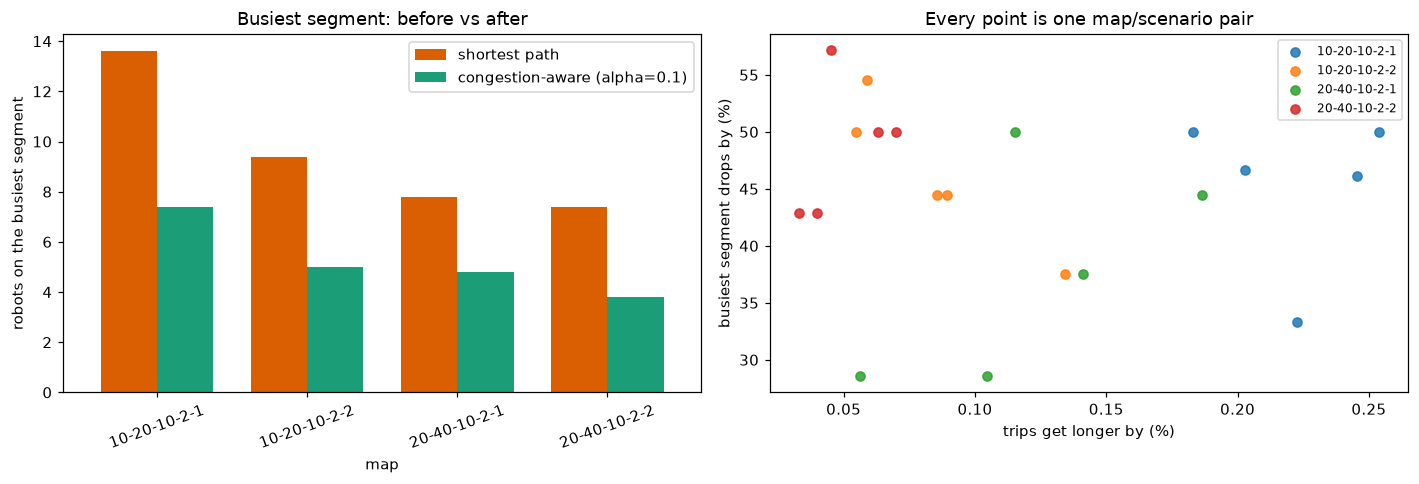

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

summary[["peak_before", "peak_after"]].plot.bar(
    ax=axes[0], color=["#d95f02", "#1b9e77"], width=0.75
)
axes[0].set_title("Busiest segment: before vs after")
axes[0].set_ylabel("robots on the busiest segment")
axes[0].set_xlabel("map")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(["shortest path", f"congestion-aware (alpha={ALPHA})"])

for map_name, group in results.groupby("map"):
    axes[1].scatter(
        group["longer_%"], group["peak_drop_%"],
        label=map_name, alpha=0.85,
    )
axes[1].set_xlabel("trips get longer by (%)")
axes[1].set_ylabel("busiest segment drops by (%)")
axes[1].set_title("Every point is one map/scenario pair")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Step 3: Zoom into one map

The table above says *on average* what happens. Now we look at **one** map/scenario pair in detail: where the traffic actually is, which cells are the hotspots, and how strong `ALPHA` should be.

We use the first map/scenario pair in `datasets`.

In [26]:
def draw_heatmap(graph, height, width, cell_use, title, ax, marked=()):
    """Colour every cell by how many robots pass through it.

    NaN = shelf/wall (dark grey), 0 = free cell nobody used (pale), >0 = robots.
    """
    picture = np.full((height, width), np.nan)
    for (x, y) in graph.nodes:
        picture[y, x] = cell_use.get((x, y), 0)

    picture = np.ma.masked_invalid(picture)
    cmap = plt.get_cmap("YlOrRd").copy()
    cmap.set_bad("#2b2b2b")

    image = ax.imshow(picture, cmap=cmap, interpolation="nearest")
    plt.colorbar(image, ax=ax, label="robots through cell", shrink=0.7)

    for (x, y) in marked:
        ax.plot(x, y, "bX", markersize=11)

    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


# The detailed example: first map/scenario pair.
example_map, example_scen = datasets[0]
example_graph = graphs[example_map.name]
example_rows = map_rows_by_name[example_map.name]
example_height = len(example_rows)
example_width = len(example_rows[0])

all_example_robots = load_robots(example_scen)
usable_example = [r for r in all_example_robots
                  if r[0] in example_graph and r[1] in example_graph and r[0] != r[1]]
example_robots = random.Random(SEED).sample(usable_example, min(NUM_ROBOTS, len(usable_example)))

base_paths, base_edges = route_robots(example_graph, example_robots, alpha=0)
aware_paths, aware_edges = route_robots(example_graph, example_robots, alpha=ALPHA)
base_cells = count_cells(base_paths)
aware_cells = count_cells(aware_paths)

print("Example:", example_map.name, "/", example_scen.name, f"({len(example_robots)} robots)")

Example: warehouse-10-20-10-2-1.map / warehouse-10-20-10-2-1-random-1.scen (200 robots)


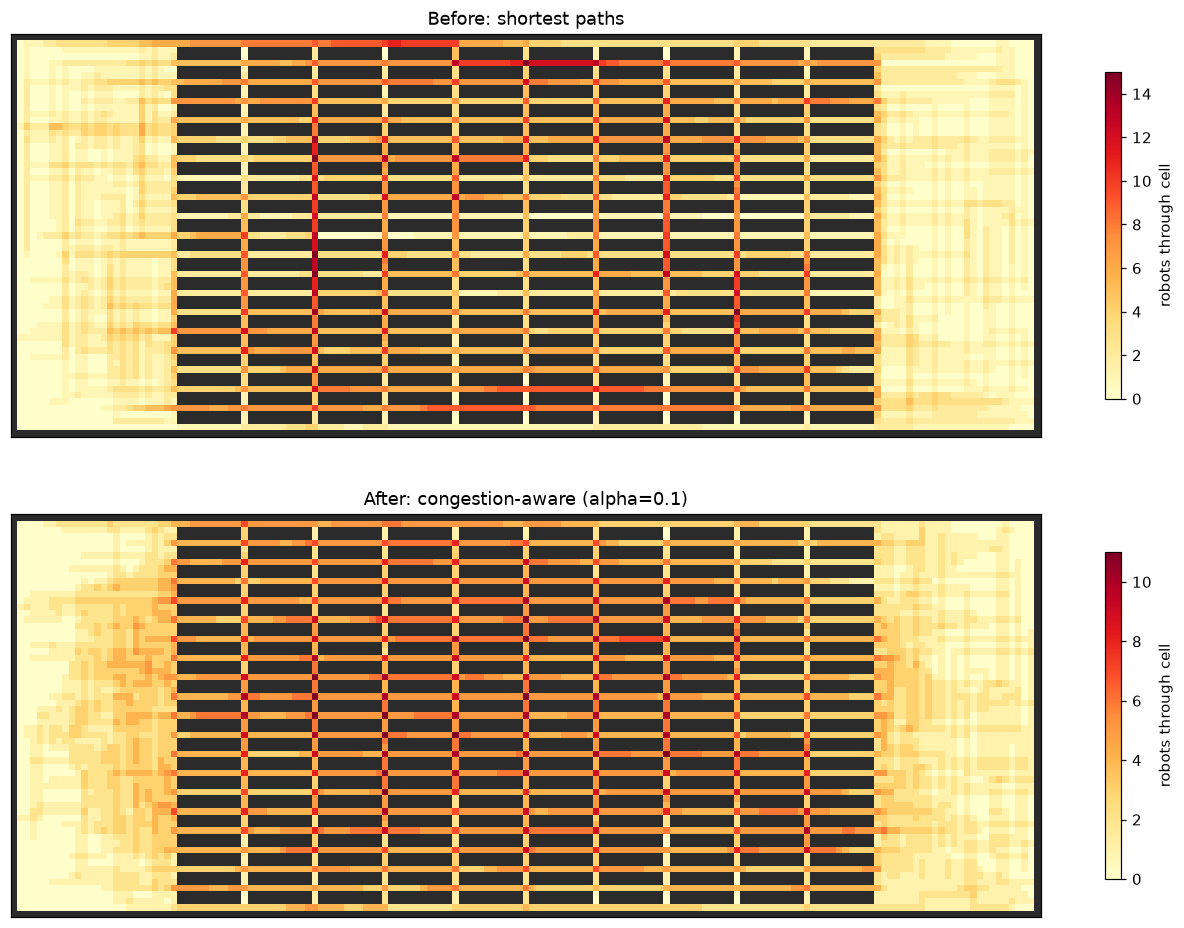

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9))
draw_heatmap(example_graph, example_height, example_width, base_cells,
             "Before: shortest paths", axes[0])
draw_heatmap(example_graph, example_height, example_width, aware_cells,
             f"After: congestion-aware (alpha={ALPHA})", axes[1])
plt.tight_layout()
plt.show()

**How to read the heatmap:** dark red = many robots pass here (hotspot), pale yellow = quiet, dark grey = shelves. The colour scales differ between the two panels, so compare the **maximum on each colour bar**, not the shades.

In [28]:
# Top 10 hotspots. Robots always start and end somewhere, so those cells are busy by definition.
start_goal_cells = set()
for start, goal in example_robots:
    start_goal_cells.add(start)
    start_goal_cells.add(goal)

# Sort the cells from busiest to quietest: (cell, number of robots).
ranked_cells = sorted(base_cells.items(), key=lambda pair: pair[1], reverse=True)

# Keep the 10 busiest cells that are not a start or goal cell.
hotspots = []
for cell, count in ranked_cells:
    if cell not in start_goal_cells:
        hotspots.append((cell, count))
hotspots = hotspots[:10]

pd.DataFrame(hotspots, columns=["cell (x, y)", "robots through it"],
             index=range(1, len(hotspots) + 1))

,"cell (x, y)",robots through it
1,"(113, 43)",15
2,"(47, 19)",15
3,"(47, 34)",15
4,"(47, 37)",15
5,"(80, 4)",15
6,"(47, 43)",14
7,"(47, 16)",14
8,"(69, 25)",13
9,"(58, 19)",13
10,"(69, 19)",13


### How strong should ALPHA be?

We try several values on the example dataset. Small ALPHA = barely avoids traffic, large ALPHA = avoids it strongly but takes longer routes.

In [29]:
sweep = []
for alpha in [0, 0.05, 0.1, 0.2, 0.5, 1.0]:
    paths, edges = route_robots(example_graph, example_robots, alpha=alpha)
    stats = summarize(paths, edges)
    sweep.append({
        "alpha": alpha,
        "avg_trip": stats["avg_trip"],
        "peak_segment": stats["peak_segment"],
        "top10_avg": stats["top10_avg"],
    })

sweep = pd.DataFrame(sweep)
sweep["longer_%"] = (100 * (sweep["avg_trip"] / sweep["avg_trip"].iloc[0] - 1)).round(2)
sweep

,alpha,avg_trip,peak_segment,top10_avg,longer_%
0,0.00,81.44,13,12.3,0.00
1,0.05,81.51,8,7.3,0.09
2,0.10,81.64,7,6.7,0.25
3,0.20,81.84,7,7.0,0.49
4,0.50,82.87,8,7.3,1.76
5,1.00,85.24,7,7.0,4.67


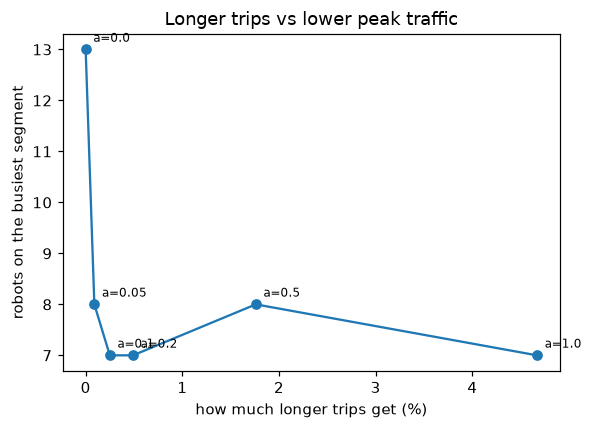

In [30]:
plt.figure(figsize=(5.5, 4))
plt.plot(sweep["longer_%"], sweep["peak_segment"], "o-")
for _, row in sweep.iterrows():
    plt.annotate(f"a={row['alpha']}", (row["longer_%"], row["peak_segment"]),
                 textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.xlabel("how much longer trips get (%)")
plt.ylabel("robots on the busiest segment")
plt.title("Longer trips vs lower peak traffic")
plt.tight_layout()
plt.show()

**Reading the chart:** moving left to right costs longer trips. The curve usually drops fast at first and then flattens, so a small-to-medium ALPHA is the sweet spot. The sweep is done on one scenario; Step 2 already showed the same pattern across all of them.

## Step 4: What if the busiest cell is blocked?

We block the #1 hotspot (for example a broken robot or a fallen box), send everyone along plain shortest paths again, and measure the damage:

- how many robots were affected,
- how much longer the total distance gets,
- whether any robot can no longer reach its goal.

In [31]:
cell_to_block = hotspots[0][0]
print("Blocking cell:", cell_to_block)

blocked_graph = example_graph.copy()
blocked_graph.remove_node(cell_to_block)
blocked_paths, blocked_edges = route_robots(blocked_graph, example_robots, alpha=0)
blocked_cells = count_cells(blocked_paths)

# Robots whose original route went through the blocked cell.
affected = [i for i, path in enumerate(base_paths) if path and cell_to_block in path]
no_route = sum(1 for path in blocked_paths if path is None)

# Compare total distance for robots that have a route both before and after.
both = [i for i in range(len(example_robots)) if base_paths[i] and blocked_paths[i]]
base_total = sum(len(base_paths[i]) - 1 for i in both)
blocked_total = sum(len(blocked_paths[i]) - 1 for i in both)
change_pct = 100 * (blocked_total - base_total) / base_total

print(f"Robots whose route used that cell: {len(affected)} of {len(example_robots)}")
print(f"Robots with no route after blocking: {no_route}")
print(f"Total distance: {base_total} -> {blocked_total} ({change_pct:+.1f}%)")
print(f"Busiest cell: {max(base_cells.values())} robots before -> {max(blocked_cells.values())} robots after")

Blocking cell: (113, 43)
Robots whose route used that cell: 15 of 200
Robots with no route after blocking: 0
Total distance: 16288 -> 16298 (+0.1%)
Busiest cell: 15 robots before -> 15 robots after


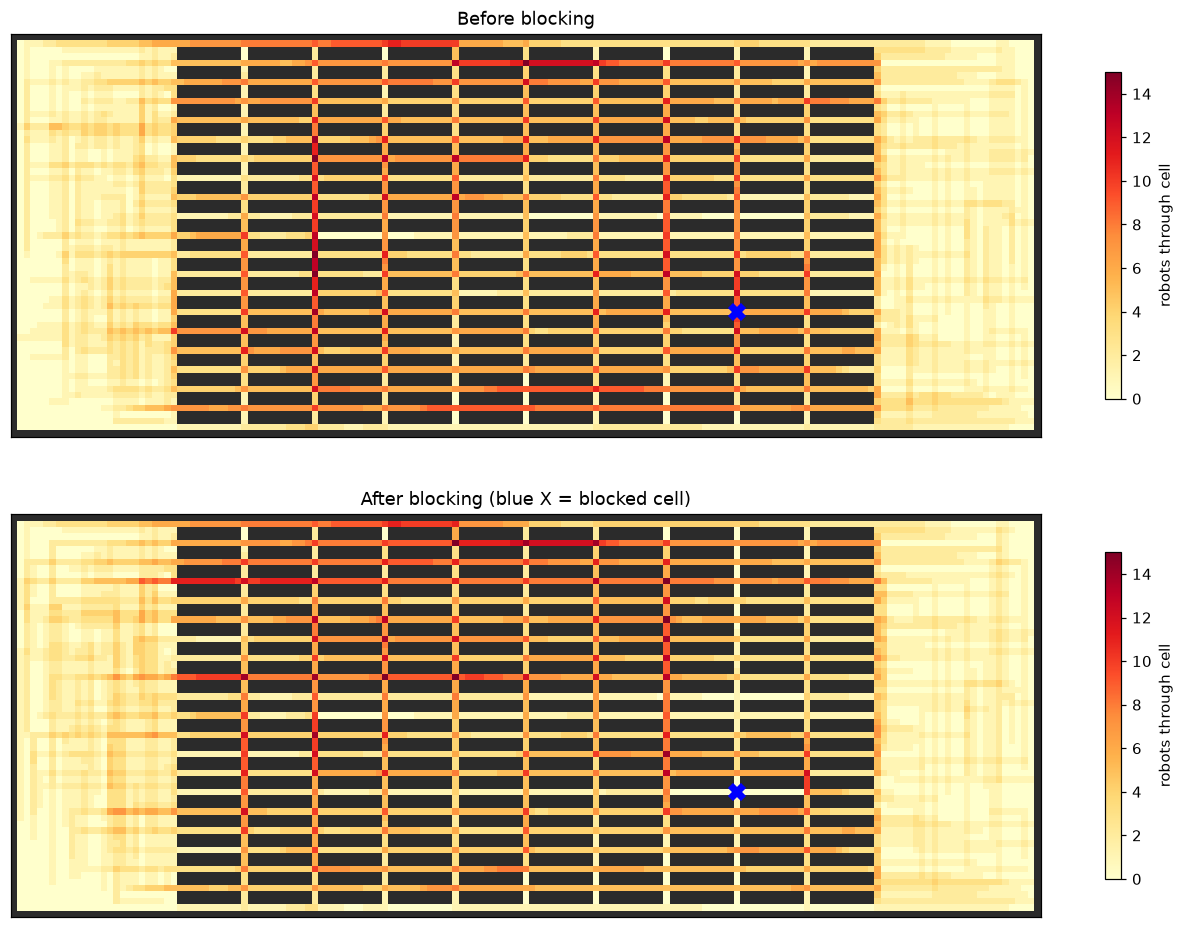

In [32]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9))
draw_heatmap(example_graph, example_height, example_width, base_cells,
             "Before blocking", axes[0], marked=[cell_to_block])
draw_heatmap(example_graph, example_height, example_width, blocked_cells,
             "After blocking (blue X = blocked cell)", axes[1], marked=[cell_to_block])
plt.tight_layout()
plt.show()

**Things to notice:** a warehouse with many parallel aisles can usually absorb one blocked cell with a tiny detour. But look at the busiest cell number: diverted robots often pile onto the cells *next to* the blocked one, so a new local hotspot can appear.

## Step 5: Summary of findings (copy into your report)

In [33]:
overall_peak_drop = summary["peak_drop_%"].mean()
overall_longer = summary["longer_%"].mean()

print(f"1. Congestion-aware routing (alpha={ALPHA}) lowers the busiest segment on every map by "
      f"{summary['peak_drop_%'].min():.0f}-{summary['peak_drop_%'].max():.0f}% "
      f"(average {overall_peak_drop:.0f}%).")
print(f"2. The price is small: average trips get {overall_longer:+.2f}% longer "
      f"(worst map {summary['longer_%'].max():+.2f}%).")
print(f"3. Over {len(results)} map/scenario pairs, the busiest segment falls from "
      f"{results['peak_before'].mean():.1f} to {results['peak_after'].mean():.1f} robots on average.")
print(f"4. Blocking the busiest cell on {example_map.stem.replace('warehouse-', '')} "
      f"changed total travel distance by {change_pct:+.1f}% and left {no_route} robots without a route.")

1. Congestion-aware routing (alpha=0.1) lowers the busiest segment on every map by 38-49% (average 45%).
2. The price is small: average trips get +0.12% longer (worst map +0.22%).
3. Over 20 map/scenario pairs, the busiest segment falls from 9.6 to 5.2 robots on average.
4. Blocking the busiest cell on 10-20-10-2-1 changed total travel distance by +0.1% and left 0 robots without a route.


## Extra: Are the results stable across scenarios?

Each row below is one map/scenario pair. If the improvement holds in every scenario, the result is not a lucky draw. The table shows the range of the two key numbers per map.

In [34]:
spread = results.groupby("map").agg(
    longer_min=("longer_%", "min"),
    longer_max=("longer_%", "max"),
    peak_drop_min=("peak_drop_%", "min"),
    peak_drop_max=("peak_drop_%", "max"),
).round(1)

spread

,longer_min,longer_max,peak_drop_min,peak_drop_max
map,,,,
10-20-10-2-1,0.2,0.3,33.3,50.0
10-20-10-2-2,0.1,0.1,37.5,54.5
20-40-10-2-1,0.1,0.2,28.6,50.0
20-40-10-2-2,0.0,0.1,42.9,57.1


If `peak_drop_min` is comfortably above zero and `longer_max` stays small, the improvement is real and consistent. Report the averages, not a single scenario.

## Limits of this study (say these in your report)

- We count **how many routes overlap**, not robots meeting at the same moment. There is no timing, waiting or collision handling, so this shows *where* traffic would build up, not real traffic jams.
- Robots are routed one at a time, so the order matters a little. The random sample and the many scenarios smooth this out, but it is still a greedy procedure, not a global optimum.
- We use `NUM_ROBOTS` sampled from 1000 pairs per scenario file (not all 1000), to keep the notebook fast.
- Blocking was tested for one cell on one map. Blocking a whole aisle, or several maps, would be a harder test.
- The graph treats `.`, `G` and `S` terrain as equally fast. Real warehouses have slower zones.

## Mini glossary

| Word | Meaning |
|---|---|
| Node | one free cell of the map |
| Edge / segment | a move between two neighbouring cells |
| Path | the list of cells a robot walks through |
| Hotspot | a cell or segment used by many robots |
| ALPHA | how strongly robots avoid busy segments |
| Heatmap | a picture of the map coloured by traffic |